# hardneg_v1：同问题错答案作负样本

**问题：** 之前的 mix 检查点在 VSI-Bench 上，用真实、打乱、全零三种场景 token 得分相同（`jepa3d/tools/blind_check.py`）。原因是 InfoNCE 的负样本只有 batch 内其他行的答案，它们提到的物体和问题不同，只看文本就能区分。

**做法：** 模型和原 InfoNCE 不变，每行加最多 3 个「同问题、错答案」的句子，新增一项四选一损失：

`loss = InfoNCE + 1.0 × CE(预测, [正确答案, 错答案…])`

- 错答案来源：VSI-590K 选择题的错误选项（按本行句式渲染）；SPAR spatial_imagination 换 left/right、above/below、closer/farther；appearance_order 换排列。数值题没有错答案，只参与 InfoNCE。
- 数据：训练 658,518 行，其中 423,044 行带错答案；每 20 个场景留出 1 个（105 个场景，6,786 行）作 holdout。
- 训练：1 epoch，6870 步，3 GPU，lr 1e-4（作业 12610，4 小时 17 分）。

**判据（跑之前定的）：** holdout 上 real − shuffled ≥ 5 个点，且至少 3 个题型各自 ≥ 5 个点。只看这个差，不看绝对准确率，因为答案先验和常识会抬高绝对值。

**结论：未达标。** 整体差 2.6 个点；只有 appearance_order 明显用上了图像，需要定位物体的题型差值都在 1 个点左右。

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "experiments" / "hardneg_v1" / "results").is_dir())
EXP = ROOT / "experiments" / "hardneg_v1"
ev = json.loads((EXP / "results" / "eval_final.json").read_text())
MODES = ("real", "shuffled", "zero")
COLORS = {"real": "#2a78d6", "shuffled": "#eb6834", "zero": "#1baf7a"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def holdout(fmt: str) -> pd.DataFrame:
    """Accuracy in percent by question type; gap = real - shuffled, with a rough
    standard error (two independent proportions; the runs share rows, so it is an upper bound)."""
    rows = {}
    for key, real in ev["real"]["holdout"].items():
        if not key.startswith(fmt + "/"):
            continue
        acc = {m: 100 * ev[m]["holdout"][key]["acc"] for m in MODES}
        p, n = real["acc"], real["rows"]
        rows[key.removeprefix(fmt + "/")] = {**acc, "chance": 100 * real["chance"], "rows": n,
                                             "gap": acc["real"] - acc["shuffled"],
                                             "gap_se": 100 * np.sqrt(2 * p * (1 - p) / n)}
    table = pd.DataFrame(rows).T.astype({"rows": int})
    return table.loc[["all", *sorted(i for i in table.index if i != "all")]]


def show(table: pd.DataFrame):
    return table.style.format("{:.1f}", subset=[c for c in table.columns if c != "rows"])

## 1. Holdout：真实 / 打乱 / 全零场景 token

长格式：正确答案句子对它的错答案句子。`gap` = real − shuffled，是图像带来的部分；`gap_se` 是这个差的大致标准误。

In [2]:
long = holdout("long")
show(long)

,real,shuffled,zero,chance,rows,gap,gap_se
all,46.7,44.1,42.8,29.9,6786,2.6,0.9
spar/appearance_order,37.7,28.8,29.3,25.0,1000,8.9,2.2
spar/spatial_imagination_oc_video_hard,44.8,43.7,45.0,31.2,1000,1.1,2.2
spar/spatial_imagination_oo_video_hard,23.6,23.3,22.0,13.3,1000,0.3,1.9
vsi590k/appearance_order,45.7,40.8,41.5,25.0,632,4.9,2.8
vsi590k/relative_count,55.2,45.5,50.6,33.3,154,9.7,5.7
vsi590k/relative_direction_object,46.1,45.8,43.2,37.3,1000,0.3,2.2
vsi590k/relative_distance_object,42.5,41.4,34.2,25.0,1000,1.1,2.2
vsi590k/relative_size_object,84.7,83.6,82.7,50.0,1000,1.1,1.6


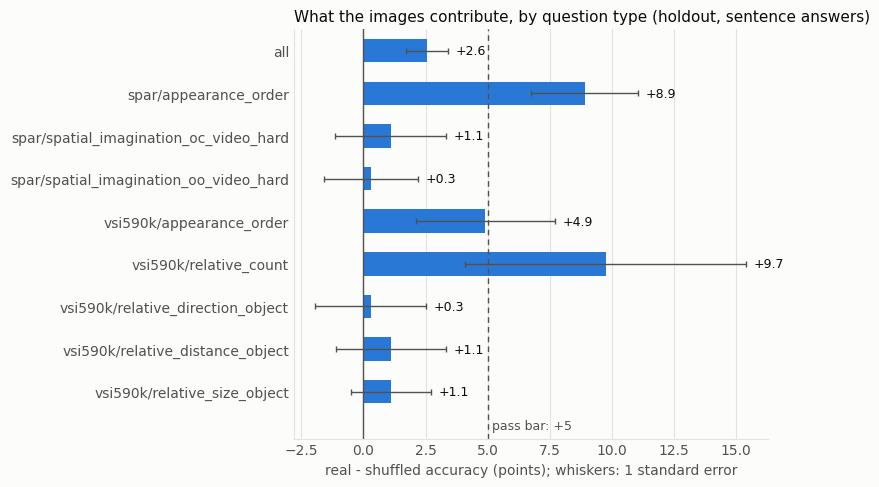

In [3]:
def gap_chart(table: pd.DataFrame, title: str):
    t = table.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(t) + 1.2))
    ax.barh(t.index, t["gap"], height=0.55, color=COLORS["real"])
    ax.errorbar(t["gap"], t.index, xerr=t["gap_se"], fmt="none", ecolor=MUTED, elinewidth=1, capsize=2)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.axvline(5, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.set_ylim(-1.1, len(t) - 0.5)
    ax.text(5, -0.95, " pass bar: +5", color=MUTED, va="bottom", fontsize=9)
    for y, (gap, se) in enumerate(zip(t["gap"], t["gap_se"])):
        ax.text(max(gap, 0) + se + 0.3, y, f"{gap:+.1f}", va="center", fontsize=9)
    ax.set_xlabel("real - shuffled accuracy (points); whiskers: 1 standard error")
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    plt.tight_layout()
    plt.show()


gap_chart(long, "What the images contribute, by question type (holdout, sentence answers)")

**读法：**

- 绝对准确率比随机高约 17 个点（46.7 对 29.9），但换成别的场景的 token 只掉 2.6 个点。高出随机的部分主要来自答案先验和常识。`relative_size_object` 最明显：不看图也有 83.6%（「桌子比鼠标长」）。
- 只有 `appearance_order` 的差值可靠（SPAR +8.9，VSI +4.9）。这类题只需要认出物体何时出现，不需要定位。
- `relative_count` 的 +9.7 只有 154 行，在噪声范围内。
- 需要定位具体物体的题型（方向、距离、spatial_imagination）差值都在 1 个点左右，和噪声同量级。

## 2. 长格式与短格式

短格式：`target_short` 对原始选项（只有 VSI-590K 选择题有）。训练只用了长格式。

In [4]:
short = holdout("short")
both = pd.DataFrame({"long real": long["real"], "short real": short["real"], "chance": short["chance"],
                     "long gap": long["gap"], "short gap": short["gap"], "rows": short["rows"]}).loc[short.index[1:]]
show(both)

,long real,short real,chance,long gap,short gap,rows
vsi590k/appearance_order,45.7,42.6,25.0,4.9,6.3,632.000000
vsi590k/relative_count,55.2,21.4,33.3,9.7,0.0,154.000000
vsi590k/relative_direction_object,46.1,46.5,37.3,0.3,0.9,1000.000000
vsi590k/relative_distance_object,42.5,30.9,25.0,1.1,-0.1,1000.000000
vsi590k/relative_size_object,84.7,50.9,50.0,1.1,-0.7,1000.000000


用句子训练学到的东西，换成短选项后大部分丢失：`relative_size_object` 从 84.7% 掉到随机水平，`relative_count` 低于随机。VSI-Bench 用原始选项评测，因此会低估按句子训练的模型。

## 3. VSI-Bench（原始问题和选项）

In [5]:
def vsibench(name: str) -> pd.DataFrame:
    table = pd.DataFrame({m: {k.removeprefix("type/"): 100 * v for k, v in ev[m][name].items()} for m in MODES})
    table["gap"] = table["real"] - table["shuffled"]
    return table


for name in ("vsibench_test_posed_f8", "vsibench_debiased_posed_f8"):
    display(vsibench(name).style.format("{:.1f}").set_caption(name))

,real,shuffled,zero,gap
all,33.7,33.2,27.4,0.4
obj_appearance_order,40.9,40.1,29.9,0.8
object_rel_direction_easy,50.8,50.0,49.2,0.8
object_rel_direction_hard,27.3,27.7,35.1,-0.4
object_rel_direction_medium,29.6,32.1,11.9,-2.5
object_rel_distance,26.2,24.9,22.5,1.3
route_planning,33.3,31.1,32.2,2.2


,real,shuffled,zero,gap
all,35.0,34.3,31.4,0.7
obj_appearance_order,36.2,36.8,31.4,-0.6
object_rel_direction_easy,51.3,50.4,49.6,0.9
object_rel_direction_hard,23.9,19.4,25.4,4.5
object_rel_direction_medium,45.9,43.2,48.6,2.7
object_rel_distance,25.8,26.3,20.1,-0.5
route_planning,34.9,28.6,31.7,6.3


真实和打乱的差在 1 个点以内，和之前的检查点一样。全零 token 更低，说明模型需要「有 token」，但不在乎是不是这个场景的 token。

## 4. 训练过程

`hard_acc`：正确答案胜过本行全部错答案的比例。训练集和 holdout 走势一致，没有过拟合；结束时仍在缓慢上升。两条 InfoNCE 曲线不能直接比高低：训练时每行有 95 个 batch 内负样本（3 GPU × 32），holdout 只有 31 个。

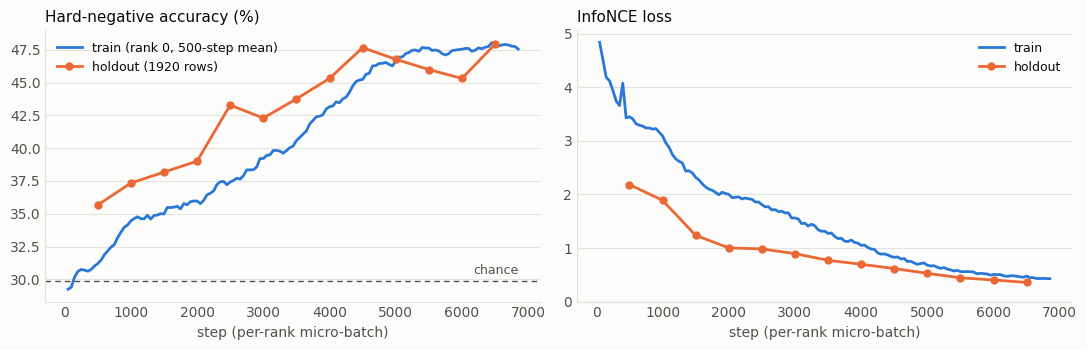

step,500,3500,6500
appearance_order,33.0,37.8,41.2
relative_count,27.5,42.5,55.0
relative_direction_object,52.3,45.8,46.2
relative_distance_object,30.8,35.3,39.9
relative_size_object,53.2,82.1,87.0
spatial_imagination_oc_video_hard,29.9,37.4,44.2
spatial_imagination_oo_video_hard,14.5,22.7,27.1


In [6]:
log = [json.loads(l) for l in open(EXP / "ckpt" / "hardneg_log.jsonl")]
train = pd.DataFrame([e for e in log if "hard_acc" in e]).set_index("step")
val = pd.DataFrame([e for e in log if "val_hard_acc" in e]).set_index("step")
steps = pd.DataFrame([json.loads(l) for l in open(EXP / "ckpt" / "train_log.jsonl")])
infonce = steps.dropna(subset=["infonce_loss"]).set_index("step")["infonce_loss"]
val_infonce = steps.dropna(subset=["val_loss"]).set_index("step")["val_loss"] if "val_loss" in steps else None

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
smooth = 100 * train["hard_acc"].rolling(10, min_periods=1).mean()
a.plot(smooth.index, smooth, color=COLORS["real"], linewidth=2, label="train (rank 0, 500-step mean)")
a.plot(val.index, 100 * val["val_hard_acc"], color=COLORS["shuffled"], linewidth=2, marker="o", markersize=5,
       label="holdout (1920 rows)")
a.axhline(100 * ev["real"]["holdout"]["long/all"]["chance"], color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
a.text(train.index[-1], 100 * ev["real"]["holdout"]["long/all"]["chance"] + 0.5, "chance", color=MUTED, ha="right", fontsize=9)
a.set_title("Hard-negative accuracy (%)", loc="left", fontsize=11)
b.plot(infonce.index, infonce, color=COLORS["real"], linewidth=2, label="train")
if val_infonce is not None:
    b.plot(val_infonce.index, val_infonce, color=COLORS["shuffled"], linewidth=2, marker="o", markersize=5, label="holdout")
b.set_title("InfoNCE loss", loc="left", fontsize=11)
b.set_ylim(0)
for ax in (a, b):
    ax.set_xlabel("step (per-rank micro-batch)")
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

types = val.filter(like="val_hard_acc_type/").rename(columns=lambda c: c.split("/")[1])
(100 * types.iloc[[0, len(types) // 2, -1]]).T.style.format("{:.1f}").set_caption("holdout hard_acc by type at three steps (%)")

## 5. 结论

1. **未达到通过线。** 整体 real − shuffled 为 +2.6 个点（要求 5），明确达标的题型只有 SPAR appearance_order 一个。
2. **模型学到的主要是答案先验。** 堵住「按物体名区分」的捷径后，模型转而利用「哪个答案更常见、更合常识」，仍然不需要看图。
3. **只在不需要定位的题型上开始用图。** appearance_order 只要认出物体是否出现及先后；方向、距离、spatial_imagination 要先在场景 token 里找到问题提到的物体，这些题型没有变化。
4. **和几何探针的结论一致。** 探针显示冻结的 3DRAE token 里有物体位置（点提示 0.27 m），但按物体名称查询时受限于名称到 token 的对应。这次从训练目标一侧得到同样的指向：瓶颈在 grounding。

**没有验证的：**

- 只训练了 1 epoch，`hard_acc` 结束时仍在上升；更长的训练是否拉开差距没有测。
- 没有训练全程不看图的对照模型，「先验能到多少」是从打乱和全零两种评测推断的。
- `gap_se` 按两个独立比例估计，是上界。

**下一步建议：** 保留错答案负样本，加 grounding 监督（EmbodiedScan 的物体框，监督问题中的物体词对应到物体所在的 token）。

**文件：** 结果 `experiments/hardneg_v1/results/eval_final.json`；训练日志 `experiments/hardneg_v1/ckpt/{hardneg_log,train_log}.jsonl`；检查点 `experiments/hardneg_v1/ckpt/final.pt`；代码 `jepa3d/{hard_negatives,trainer}.py`、`jepa3d/tools/{add_hard_negatives,eval_holdout}.py`、配置 `jepa3d/configs/hardneg_v1.yaml`。